
# TP3 — Análisis exploratorio de estaciones meteorológicas

**Materia:** Taller de Análisis de Datos I  
**Trabajo Práctico:** N.º 3  
**Etapa:** Análisis exploratorio de estaciones

## 1. Introducción

El presente notebook analiza las características y la distribución de las estaciones meteorológicas incluidas en el dataset.

El objetivo es investigar si existen diferencias en la disponibilidad de observaciones y en los errores de temperatura entre estaciones y regiones geográficas.

Este análisis permitirá comprender la variabilidad espacial de los errores y fundamentar la incorporación de variables geográficas en los modelos de Machine Learning.

## 2. Objetivos

- Identificar la cantidad de estaciones meteorológicas.
- Analizar su distribución geográfica.
- Examinar la cantidad de registros disponibles por estación.
- Investigar diferencias en la cobertura de observaciones.
- Analizar el error de temperatura según la estación.
- Comparar el comportamiento de los horizontes de 12 y 24 horas.
- Explorar la posible utilidad de estaciones geográficamente cercanas.

## 3. Criterios de selección

Se trabajará directamente con los archivos CSV originales, sin modificarlos.

Se utilizarán 48 archivos, excluyendo el período comprendido entre el 22 y el 26 de octubre de 2026, debido a la anomalía de cobertura documentada en el notebook 00.

Para el análisis principal del error se priorizarán los registros con emparejamiento `interval` y temperaturas pronosticadas y observadas disponibles.

Se conservará el orden cronológico y se evitará utilizar información futura al construir variables para el modelado.


In [1]:

# ==========================================
# 1. LIBRERÍAS Y CONFIGURACIÓN DEL DATASET
# ==========================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identificar la carpeta del dataset
DIRECTORIO_ACTUAL = Path.cwd()

rutas_posibles = [
    DIRECTORIO_ACTUAL / "dataset",
    DIRECTORIO_ACTUAL.parent / "dataset"
]

DATASET_DIR = next(
    (ruta for ruta in rutas_posibles if ruta.is_dir()),
    None
)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta dataset."
    )

# Identificar los archivos originales
archivos = sorted(
    DATASET_DIR.glob("forecast_observation_*.csv")
)

# Fechas excluidas según criterio del docente
fechas_excluidas = {
    f"forecast_observation_2026_10_{dia:02d}.csv"
    for dia in range(22, 27)
}

# Seleccionar los archivos que utilizaremos
archivos_analisis = [
    archivo for archivo in archivos
    if archivo.name not in fechas_excluidas
]

# Mostrar configuración
print("Carpeta del dataset:")
print(DATASET_DIR)

print("\nArchivos originales:", len(archivos))
print("Archivos excluidos:", len(archivos) - len(archivos_analisis))
print("Archivos para el análisis:", len(archivos_analisis))

print("\nPrimer archivo seleccionado:")
print(archivos_analisis[0].name)

print("\nÚltimo archivo seleccionado:")
print(archivos_analisis[-1].name)

print("\nLibrerías cargadas correctamente.")


Carpeta del dataset:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\dataset

Archivos originales: 53
Archivos excluidos: 5
Archivos para el análisis: 48

Primer archivo seleccionado:
forecast_observation_2026_09_10.csv

Último archivo seleccionado:
forecast_observation_2026_11_01.csv

Librerías cargadas correctamente.


In [2]:

# ==========================================
# 2. IDENTIFICACIÓN DE ESTACIONES METEOROLÓGICAS
# ==========================================

columnas_estaciones = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "horizon_target_hours"
]

# Leer solamente las columnas necesarias
archivo_ejemplo = archivos_analisis[0]

df_estaciones = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_estaciones,
    low_memory=False
)

# Seleccionar los horizontes estudiados
df_estaciones = df_estaciones[
    df_estaciones["horizon_target_hours"].isin([12, 24])
].copy()

# Identificar combinaciones únicas de estación y ubicación
metadatos_estaciones = (
    df_estaciones[
        ["station_id", "state", "latitude", "longitude"]
    ]
    .drop_duplicates()
)

print("Archivo analizado:", archivo_ejemplo.name)
print("Registros de 12 y 24 h:", len(df_estaciones))

print("\nEstaciones diferentes:")
print(df_estaciones["station_id"].nunique())

print("\nEstados o regiones diferentes:")
print(df_estaciones["state"].nunique())

print("\nEstaciones con coordenadas faltantes:")
print(
    metadatos_estaciones[
        ["latitude", "longitude"]
    ].isna().any(axis=1).sum()
)

# Comprobar inconsistencias de ubicación
ubicaciones_por_estacion = (
    metadatos_estaciones
    .groupby("station_id")
    .size()
)

print("\nEstaciones con diferentes datos geográficos:")
print((ubicaciones_por_estacion > 1).sum())

# Distribución de estaciones por estado
print("\nEstaciones por estado (primeros 10):")

estaciones_por_estado = (
    metadatos_estaciones
    .groupby("state")["station_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(estaciones_por_estado.head(10))


Archivo analizado: forecast_observation_2026_09_10.csv
Registros de 12 y 24 h: 24912

Estaciones diferentes:
519

Estados o regiones diferentes:
23

Estaciones con coordenadas faltantes:
0

Estaciones con diferentes datos geográficos:
0

Estaciones por estado (primeros 10):


state
TN    24
SC    24
NY    24
KY    23
AL    23
CT    23
FL    23
NJ    23
NH    23
GA    23
Name: station_id, dtype: int64

Interpretación de las estaciones

¿Qué encontramos?

1. 519 estaciones diferentes: es una cantidad considerable para analizar diferencias geográficas en el error meteorológico.
2. 23 estados o regiones: los códigos TN, SC, NY, etc., corresponden aparentemente a estados de Estados Unidos. Esto es importante para interpretar la distribución espacial.
3. Sin coordenadas faltantes: todas las estaciones identificadas cuentan con latitud y longitud.
4. Sin inconsistencias geográficas: ninguna estación presenta distintas combinaciones de estado y coordenadas dentro del archivo analizado

Distribución completa de estaciones:


,cantidad_estaciones
state,
TN,24
SC,24
NY,24
KY,23
AL,23
CT,23
FL,23
NJ,23
NH,23


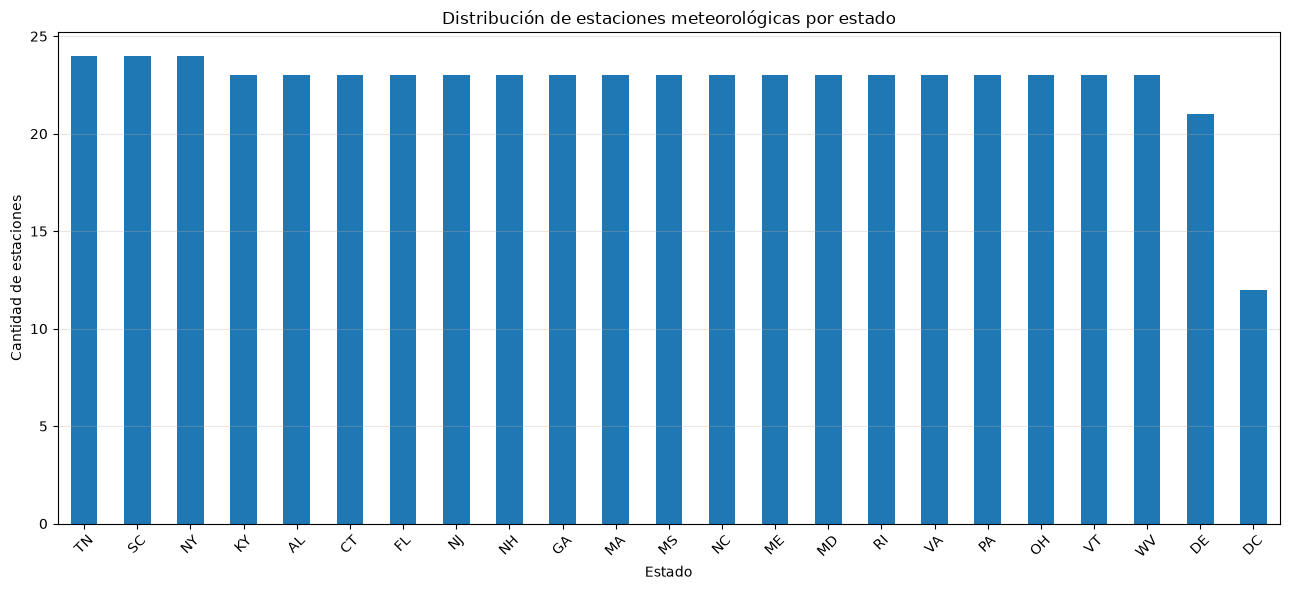

In [3]:

# ==========================================
# 3. DISTRIBUCIÓN DE ESTACIONES POR ESTADO
# ==========================================

# Contar estaciones diferentes por estado
distribucion_estados = (
    metadatos_estaciones
    .groupby("state")["station_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Distribución completa de estaciones:")
display(distribucion_estados.to_frame("cantidad_estaciones"))

# Crear gráfico
fig, ax = plt.subplots(figsize=(13, 6))

distribucion_estados.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Distribución de estaciones meteorológicas por estado"
)

ax.set_xlabel("Estado")
ax.set_ylabel("Cantidad de estaciones")

ax.grid(
    axis="y",
    alpha=0.3
)

ax.tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()
plt.show()



### 3.1. Interpretación de la distribución de estaciones

Se analizó la distribución de las 519 estaciones meteorológicas identificadas en el archivo del 10 de septiembre de 2026, agrupándolas según su estado o región.

**Resultados:**

- Se identificaron 23 estados o regiones.
- Tennessee (TN), South Carolina (SC) y New York (NY) presentan 24 estaciones cada uno.
- La mayoría de los estados tienen 23 estaciones.
- Delaware (DE) presenta 21 estaciones y Washington, D. C. (DC), 12.

**Interpretación:**

La cantidad de estaciones está distribuida de forma relativamente uniforme entre las regiones, aunque existen algunas diferencias.

Esta distribución no garantiza una cobertura espacial homogénea ni una disponibilidad equivalente de observaciones.

**Implicancias para el modelado:**

Se investigará si el error de temperatura presenta diferencias entre estaciones y regiones geográficas.

También se evaluará la utilidad de incorporar la identificación de estación, las coordenadas geográficas y las estaciones vecinas como información predictiva.


c:\Users\Jorge\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Jorge\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Jorge\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\Jorge\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_1_states_provinces_lakes.zip
  warnings.w

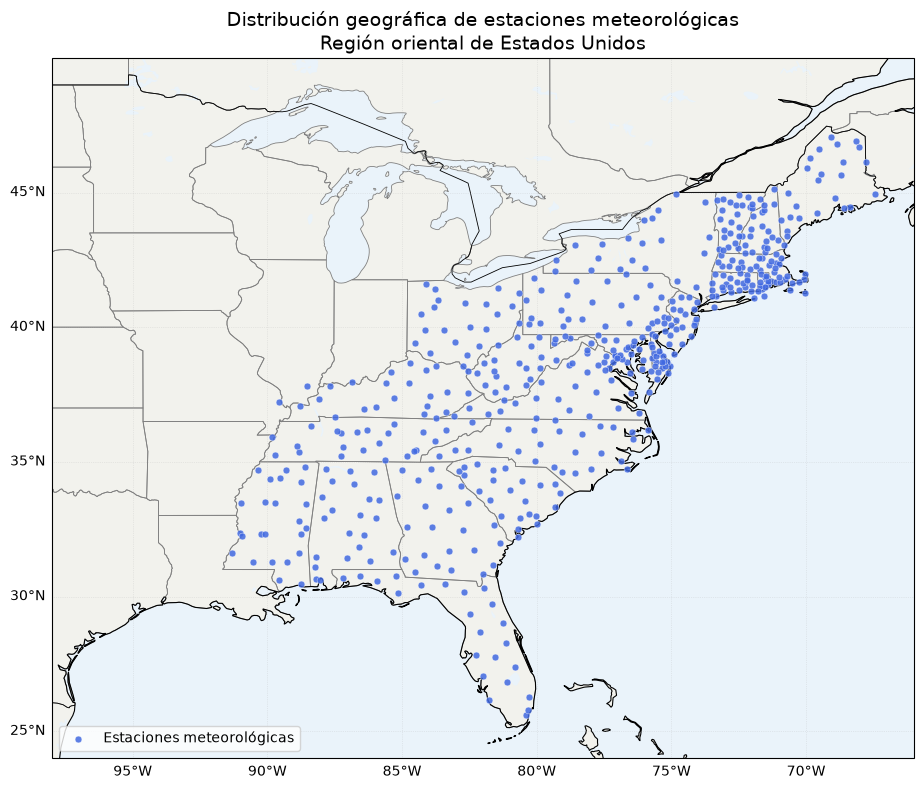

In [9]:

# ==========================================
# 4. MAPA GEOGRÁFICO REAL DE ESTACIONES
# ==========================================

import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Una fila por estación
ubicaciones = metadatos_estaciones.drop_duplicates(
    subset="station_id"
).copy()

# Proyección geográfica
proyeccion = ccrs.PlateCarree()

fig = plt.figure(figsize=(13, 8))
ax = plt.axes(projection=proyeccion)

# Mostrar la región oriental de Estados Unidos
ax.set_extent(
    [-98, -66, 24, 50],
    crs=proyeccion
)

# Capas geográficas reales
ax.add_feature(
    cfeature.OCEAN,
    facecolor="#eaf3fa"
)

ax.add_feature(
    cfeature.LAND,
    facecolor="#f2f2ed"
)

ax.add_feature(
    cfeature.LAKES,
    facecolor="#eaf3fa"
)

ax.add_feature(
    cfeature.STATES,
    edgecolor="gray",
    linewidth=0.6
)

ax.add_feature(
    cfeature.COASTLINE,
    edgecolor="black",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.6
)

# Superponer estaciones meteorológicas
ax.scatter(
    ubicaciones["longitude"],
    ubicaciones["latitude"],
    s=24,
    color="royalblue",
    edgecolor="white",
    linewidth=0.3,
    alpha=0.85,
    transform=proyeccion,
    zorder=5,
    label="Estaciones meteorológicas"
)

# Cuadrícula geográfica
grid = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    linestyle=":",
    alpha=0.4
)

grid.top_labels = False
grid.right_labels = False

ax.set_title(
    "Distribución geográfica de estaciones meteorológicas\n"
    "Región oriental de Estados Unidos",
    fontsize=14
)

ax.legend(loc="lower left")

plt.tight_layout()
plt.show()


In [10]:

# ==========================================
# 5. COBERTURA DE OBSERVACIONES POR ESTACIÓN
# ==========================================

columnas_cobertura_estaciones = [
    "station_id",
    "state",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

# Leer únicamente las columnas necesarias
df_cobertura_est = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_cobertura_estaciones,
    low_memory=False
)

# Seleccionar horizontes 12 y 24 horas
df_cobertura_est = df_cobertura_est[
    df_cobertura_est["horizon_target_hours"].isin([12, 24])
].copy()

# Identificar registros con ambas temperaturas
df_cobertura_est["temperaturas_validas"] = (
    df_cobertura_est["temperature_forecast_c"].notna()
    & df_cobertura_est["temperature_observed_c"].notna()
)

# Identificar registros válidos de tipo interval
df_cobertura_est["interval_valido"] = (
    df_cobertura_est["temperaturas_validas"]
    & (df_cobertura_est["match_type"] == "interval")
)

# Agrupar por estación y horizonte
resumen_estaciones = (
    df_cobertura_est
    .groupby(
        ["station_id", "state", "horizon_target_hours"]
    )
    .agg(
        registros=("temperaturas_validas", "size"),
        validos=("temperaturas_validas", "sum"),
        interval_validos=("interval_valido", "sum")
    )
    .reset_index()
)

# Calcular cobertura porcentual
resumen_estaciones["cobertura_pct"] = (
    resumen_estaciones["validos"]
    / resumen_estaciones["registros"]
    * 100
)

# Resumen estadístico
print("Cobertura por estación y horizonte (%):")

display(
    resumen_estaciones
    .groupby("horizon_target_hours")["cobertura_pct"]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

# Estaciones con menor cobertura a 12 horas
print("\nDiez estaciones con menor cobertura a 12 h:")

display(
    resumen_estaciones[
        resumen_estaciones["horizon_target_hours"] == 12
    ]
    .nsmallest(10, "cobertura_pct")
    [
        [
            "station_id",
            "state",
            "registros",
            "validos",
            "interval_validos",
            "cobertura_pct"
        ]
    ]
    .round(2)
)


Cobertura por estación y horizonte (%):


,count,min,median,max
horizon_target_hours,,,,
12,519,0.0,95.83,100.0
24,519,0.0,95.83,100.0



Diez estaciones con menor cobertura a 12 h:


,station_id,state,registros,validos,interval_validos,cobertura_pct
152,CNSA1,AL,24,0,0,0.00
176,D4375,NC,24,0,0,0.00
248,DY022,VA,24,0,0,0.00
276,E4436,VA,24,0,0,0.00
324,F2182,PA,24,0,0,0.00
336,F3881,MD,24,0,0,0.00
782,KLOM,PA,24,0,0,0.00
956,KVAY,NJ,24,0,0,0.00
72,AS900,OH,24,1,1,4.17
80,AT743,FL,24,1,1,4.17


¿Qué vamos a interpretar?
Nos interesa saber si las estaciones tienen porcentajes similares de observaciones disponibles o si algunas presentan problemas particulares.

Es importante separar dos conceptos:
- Cobertura: cuántos registros tienen ambas temperaturas disponibles.
- Precisión: cuánto se equivoca el pronóstico cuando tenemos una observación válida.

Aunque la cobertura mediana por estación es alta, existen estaciones que prácticamente no aportan observaciones válidas.
Esto puede influir en los modelos y, especialmente, en los baselines por estación

Interpretación de la cobertura por estación

| Indicador |	Horizonte 12 h |	Horizonte 24 h |
|-----------|------------------|-------------------|
|Estaciones analizadas |	519 |	519 |
| Cobertura mínima |	0 % |	0 % |
| Cobertura mediana |	95,83 % |	95,83 % |
| Cobertura máxima |	100 % |	100 % |

¿Qué descubrimos?
1. La estación mediana tiene una cobertura muy alta. Un valor de 95,83 % equivale a 23 de 24 registros con ambas temperaturas disponibles.

2. Hay estaciones sin ninguna observación válida. En la tabla aparecen ocho estaciones con cobertura del 0 %, distribuidas entre Alabama, Carolina del Norte, Virginia, Pensilvania, Maryland y Nueva Jersey.

3. Hay una diferencia importante entre la cobertura global y la mediana por estación.

Recordemos:
- Cobertura global del primer archivo: 70,26 %.
- Cobertura mediana por estación: 95,83 %.
Esto no es una contradicción. La mediana representa la estación central al ordenar sus coberturas, mientras que el porcentaje global incorpora los registros de todas las estaciones. Algunas estaciones con cobertura muy baja reducen considerablemente el resultado global.

Conclusión provisional: la disponibilidad de observaciones no es homogénea entre estaciones.

Estaciones representadas: 519
Estaciones sin cobertura calculada: 0


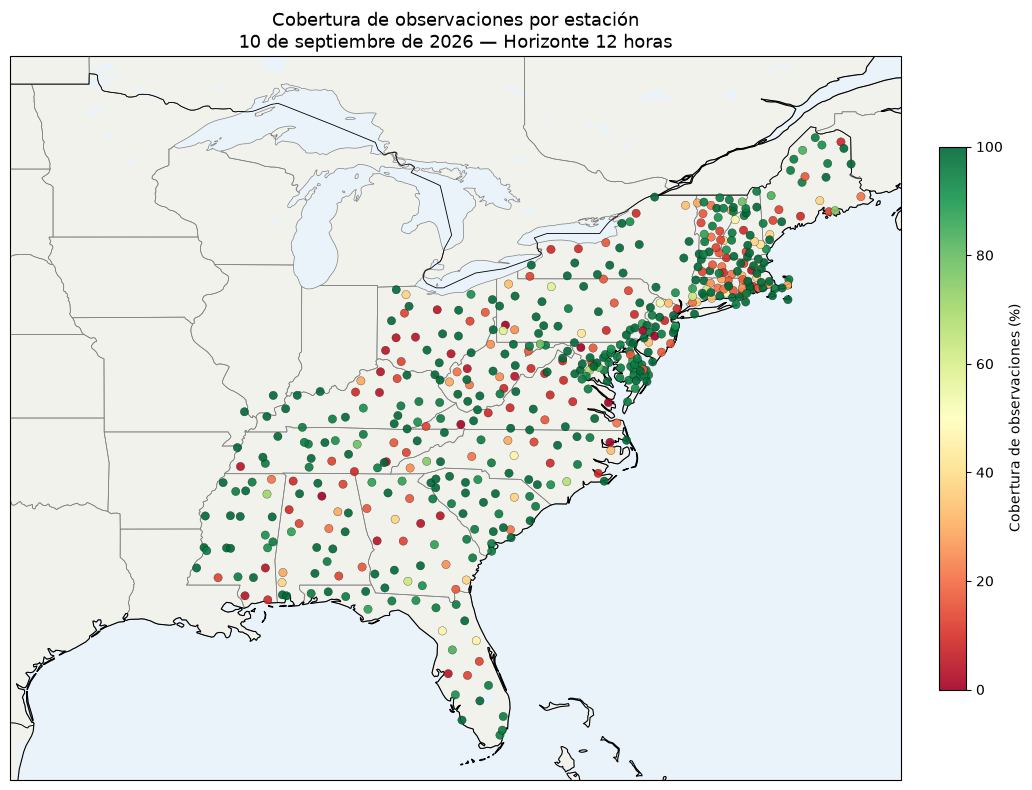

In [11]:

# ==========================================
# 6. MAPA DE COBERTURA POR ESTACIÓN
# ==========================================

# Seleccionar cobertura del horizonte de 12 horas
cobertura_12h = resumen_estaciones[
    resumen_estaciones["horizon_target_hours"] == 12
][
    ["station_id", "cobertura_pct"]
].copy()

# Asociar cobertura con coordenadas geográficas
mapa_cobertura = ubicaciones[
    ["station_id", "latitude", "longitude"]
].merge(
    cobertura_12h,
    on="station_id",
    how="left",
    validate="one_to_one"
)

print("Estaciones representadas:", len(mapa_cobertura))
print(
    "Estaciones sin cobertura calculada:",
    mapa_cobertura["cobertura_pct"].isna().sum()
)

# Crear mapa geográfico
proyeccion = ccrs.PlateCarree()

fig, ax = plt.subplots(
    figsize=(13, 8),
    subplot_kw={"projection": proyeccion}
)

ax.set_extent([-98, -66, 24, 50], crs=proyeccion)

# Capas cartográficas
ax.add_feature(cfeature.OCEAN, facecolor="#eaf3fa")
ax.add_feature(cfeature.LAND, facecolor="#f2f2ed")
ax.add_feature(cfeature.LAKES, facecolor="#eaf3fa")
ax.add_feature(
    cfeature.STATES,
    edgecolor="gray",
    linewidth=0.5
)
ax.add_feature(
    cfeature.COASTLINE,
    edgecolor="black",
    linewidth=0.8
)
ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.6
)

# Estaciones coloreadas según cobertura
puntos = ax.scatter(
    mapa_cobertura["longitude"],
    mapa_cobertura["latitude"],
    c=mapa_cobertura["cobertura_pct"],
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    s=36,
    edgecolor="black",
    linewidth=0.2,
    alpha=0.9,
    transform=proyeccion,
    zorder=5
)

# Escala de colores
barra = fig.colorbar(
    puntos,
    ax=ax,
    shrink=0.75,
    pad=0.03
)

barra.set_label("Cobertura de observaciones (%)")

# Título
ax.set_title(
    "Cobertura de observaciones por estación\n"
    "10 de septiembre de 2026 — Horizonte 12 horas",
    fontsize=13
)

plt.tight_layout()
plt.show()


¿Por qué este gráfico es útil?
El mapa nos permitirá responder una pregunta diferente a la del gráfico anterior:

¿Las estaciones con poca disponibilidad se concentran en determinadas zonas geográficas o están dispersas?

Eso es importante porque, si la ausencia de observaciones tiene un patrón espacial, podría afectar la representatividad geográfica de nuestro conjunto de entrenamiento.

El mapa utiliza los mismos datos ya cargados en memoria. No vuelve a leer los archivos originales.

In [12]:
# ==========================================
# 7. COBERTURA ACUMULADA POR ESTACIÓN
#    EN LOS 48 ARCHIVOS SELECCIONADOS
# ==========================================

columnas_periodo_estaciones = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

resultados_periodo = []

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_periodo_estaciones,
        chunksize=100_000,
        low_memory=False
    ):
        # Solo horizontes de interés
        bloque = bloque[
            bloque["horizon_target_hours"].isin([12, 24])
        ].copy()

        # Indicadores de disponibilidad
        bloque["temperaturas_validas"] = (
            bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        bloque["interval_valido"] = (
            bloque["temperaturas_validas"]
            & (bloque["match_type"] == "interval")
        )

        resumen_bloque = (
            bloque.groupby(
                ["station_id", "state", "latitude", "longitude", "horizon_target_hours"],
                dropna=False
            )
            .agg(
                registros=("temperaturas_validas", "size"),
                validos=("temperaturas_validas", "sum"),
                interval_validos=("interval_valido", "sum")
            )
            .reset_index()
        )

        resultados_periodo.append(resumen_bloque)

# Unificar resultados de todos los bloques
df_periodo_estaciones = pd.concat(
    resultados_periodo,
    ignore_index=True
)

# Sumar por estación y horizonte
df_periodo_estaciones = (
    df_periodo_estaciones
    .groupby(
        ["station_id", "state", "latitude", "longitude", "horizon_target_hours"],
        dropna=False
    )[
        ["registros", "validos", "interval_validos"]
    ]
    .sum()
    .reset_index()
)

# Calcular coberturas
df_periodo_estaciones["cobertura_pct"] = (
    df_periodo_estaciones["validos"]
    / df_periodo_estaciones["registros"]
    * 100
)

df_periodo_estaciones["interval_cobertura_pct"] = (
    df_periodo_estaciones["interval_validos"]
    / df_periodo_estaciones["registros"]
    * 100
)

print("Resumen acumulado por estación y horizonte:")
display(
    df_periodo_estaciones
    .groupby("horizon_target_hours")[["cobertura_pct", "interval_cobertura_pct"]]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

print("\nDiez estaciones con menor cobertura acumulada a 12 h:")
display(
    df_periodo_estaciones[
        df_periodo_estaciones["horizon_target_hours"] == 12
    ]
    .nsmallest(10, "cobertura_pct")[
        [
            "station_id", "state", "registros",
            "validos", "interval_validos",
            "cobertura_pct", "interval_cobertura_pct"
        ]
    ].round(2)
)

print("\nDiez estaciones con mayor cobertura acumulada a 12 h:")
display(
    df_periodo_estaciones[
        df_periodo_estaciones["horizon_target_hours"] == 12
    ]
    .nlargest(10, "cobertura_pct")[
        [
            "station_id", "state", "registros",
            "validos", "interval_validos",
            "cobertura_pct", "interval_cobertura_pct"
        ]
    ].round(2)
)

Resumen acumulado por estación y horizonte:


cobertura_pct                    interval_cobertura_pct  \
                             count  min median    max                  count   
horizon_target_hours                                                           
12                             519  1.3  86.27  99.39                    519   
24                             519  1.3  86.27  99.39                    519   

                                          
                       min median    max  
horizon_target_hours                      
12                    1.22  79.24  93.83  
24                    1.22  79.51  93.83


Diez estaciones con menor cobertura acumulada a 12 h:


,station_id,state,registros,validos,interval_validos,cobertura_pct,interval_cobertura_pct
162,CT039,CT,1151,15,14,1.30,1.22
260,E2460,RI,1147,28,27,2.44,2.35
374,F9797,KY,1151,42,41,3.65,3.56
1018,TFBM6,MS,1147,107,76,9.33,6.63
152,CNSA1,AL,1151,112,75,9.73,6.52
324,F2182,PA,1147,149,105,12.99,9.15
76,AT326,TN,1147,198,181,17.26,15.78
232,DE048,DE,1151,204,193,17.72,16.77
118,AX228,MA,1151,267,253,23.20,21.98
200,D7933,AL,1146,286,273,24.96,23.82



Diez estaciones con mayor cobertura acumulada a 12 h:


,station_id,state,registros,validos,interval_validos,cobertura_pct,interval_cobertura_pct
896,KPVD,RI,1147,1140,1076,99.39,93.81
820,KMMK,CT,1151,1143,1080,99.30,93.83
574,KBOS,RI,1147,1139,1074,99.30,93.64
638,KDYL,NJ,1147,1139,1074,99.30,93.64
804,KMGW,WV,1147,1139,1076,99.30,93.81
878,KPHL,NJ,1147,1139,1071,99.30,93.37
892,KPSF,NY,1147,1139,1074,99.30,93.64
898,KPYM,RI,1147,1139,1075,99.30,93.72
726,KHUL,ME,1151,1142,1075,99.22,93.40
816,KMLT,ME,1151,1142,1073,99.22,93.22


¿Qué descubrimos?
1. La mayoría central de las estaciones tiene buena cobertura, pero hay diferencias muy grandes entre los extremos.

Por ejemplo:
- CT039 (Connecticut): solamente 15 observaciones válidas de 1.151 registros, una cobertura del 1,30 %.
- E2460 (Rhode Island): 28 observaciones válidas de 1.147, una cobertura del 2,44 %.
- KPVD (Rhode Island): 1.140 observaciones válidas de 1.147, una cobertura del 99,39 %.
2. La cobertura interval es menor que la cobertura total. Esto es esperable porque excluye los emparejamientos fallback. Para nuestros modelos principales nos interesa especialmente la primera.

3. Algunas estaciones presentan problemas persistentes. Ya no hablamos de un solo día: hay estaciones con cobertura extremadamente baja durante el período analizado.

Esto puede afectar a los baselines por estación. Si utilizamos apenas 14 observaciones de una estación para calcular su error promedio, la estimación será mucho menos estable que si utilizamos más de 1.000.

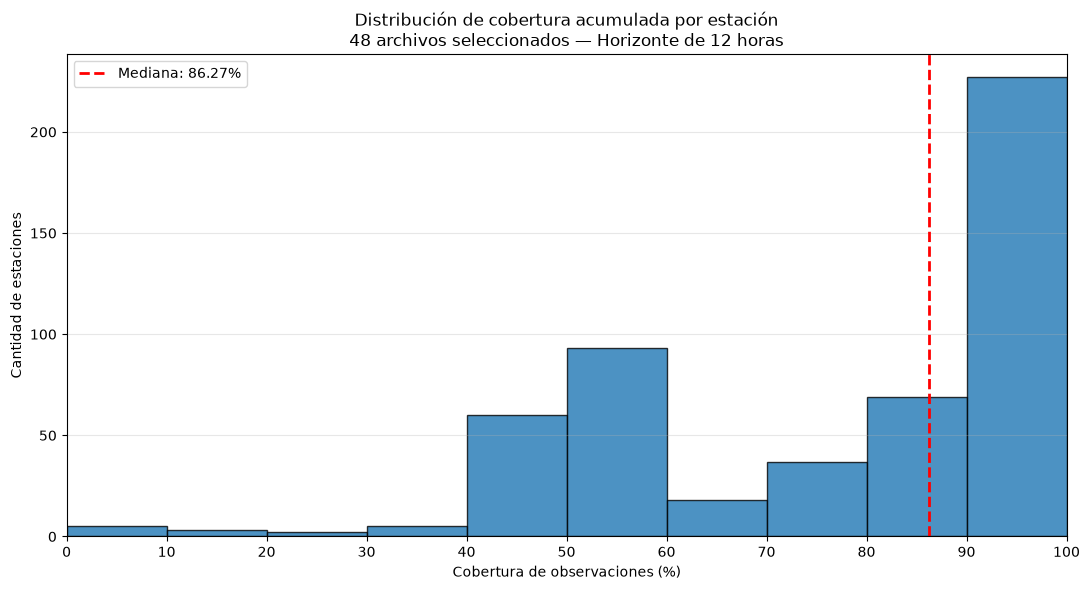

Estaciones con cobertura inferior al 50 %:
75

Estaciones con cobertura de al menos 80 %:
296

Estaciones con cobertura de al menos 90 %:
227


In [13]:

# ==========================================
# 8. DISTRIBUCIÓN DE COBERTURA POR ESTACIÓN
# ==========================================

# Seleccionar el horizonte de 12 horas
cobertura_12h_periodo = df_periodo_estaciones[
    df_periodo_estaciones["horizon_target_hours"] == 12
].copy()

# Crear histograma
fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    cobertura_12h_periodo["cobertura_pct"],
    bins=np.arange(0, 111, 10),
    edgecolor="black",
    alpha=0.8
)

# Mediana de cobertura
mediana = cobertura_12h_periodo["cobertura_pct"].median()

ax.axvline(
    mediana,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:.2f}%"
)

ax.set_title(
    "Distribución de cobertura acumulada por estación\n"
    "48 archivos seleccionados — Horizonte de 12 horas"
)

ax.set_xlabel("Cobertura de observaciones (%)")
ax.set_ylabel("Cantidad de estaciones")

ax.set_xticks(np.arange(0, 101, 10))
ax.set_xlim(0, 100)

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# Resumen por niveles de cobertura
print("Estaciones con cobertura inferior al 50 %:")
print((cobertura_12h_periodo["cobertura_pct"] < 50).sum())

print("\nEstaciones con cobertura de al menos 80 %:")
print((cobertura_12h_periodo["cobertura_pct"] >= 80).sum())

print("\nEstaciones con cobertura de al menos 90 %:")
print((cobertura_12h_periodo["cobertura_pct"] >= 90).sum())



### 8.1. Interpretación de la cobertura acumulada

Se analizó la distribución de la cobertura de observaciones por estación meteorológica utilizando los 48 archivos seleccionados y el horizonte de 12 horas.

**Resultados:**

- Se analizaron 519 estaciones meteorológicas.
- La cobertura mediana fue del 86,27 %.
- 75 estaciones (14,5 %) presentaron una cobertura inferior al 50 %.
- 296 estaciones (57,0 %) alcanzaron una cobertura de al menos el 80 %.
- 227 estaciones (43,7 %) alcanzaron una cobertura de al menos el 90 %.

**Interpretación:**

La distribución no es uniforme. Existe una concentración importante de estaciones con cobertura alta, pero también un grupo significativo con disponibilidad intermedia o baja.

Esta heterogeneidad puede afectar la cantidad de información disponible para estimar el error de temperatura de cada estación.

**Decisión metodológica:**

No se excluirán estaciones automáticamente por su cobertura. Antes de establecer criterios adicionales se analizarán sus errores y la cantidad de observaciones disponibles.

Para el modelado principal se priorizarán los registros con emparejamiento `interval` y ambas temperaturas disponibles.


Estaciones representadas: 519


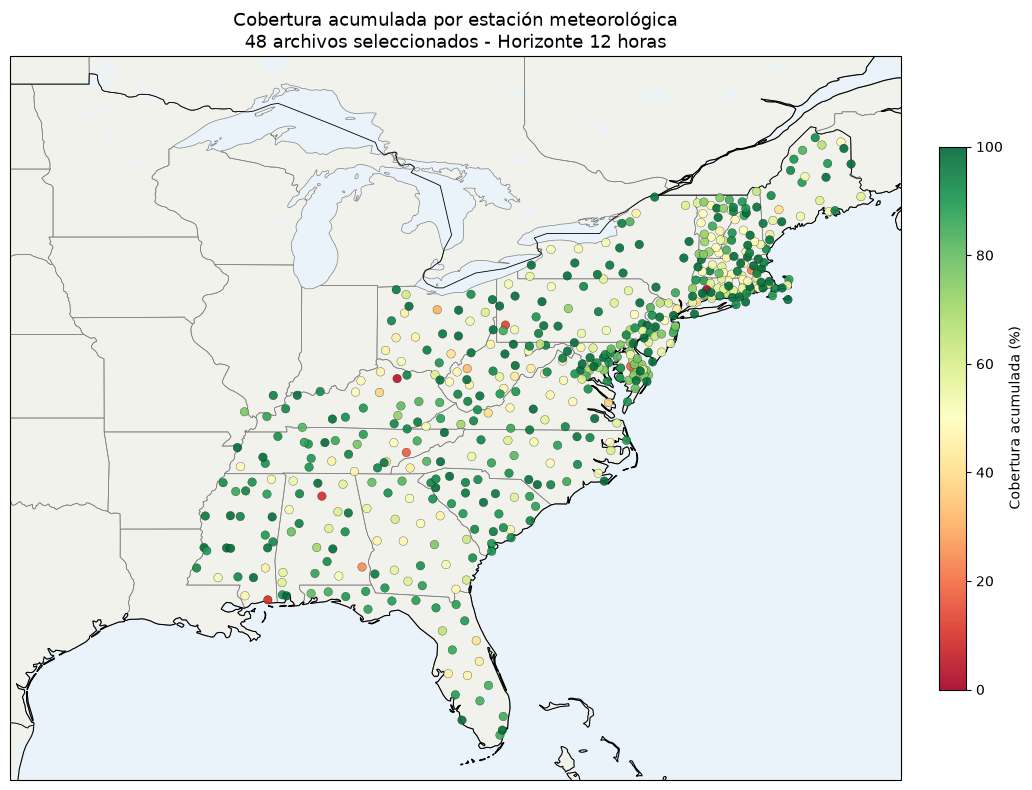

In [14]:

# ==========================================
# 9. MAPA DE COBERTURA ACUMULADA
#    48 ARCHIVOS - HORIZONTE 12 H
# ==========================================

# Seleccionar las estaciones del horizonte 12 h
mapa_periodo = df_periodo_estaciones[
    df_periodo_estaciones["horizon_target_hours"] == 12
].copy()

print("Estaciones representadas:", len(mapa_periodo))

# Preparar figura
proyeccion = ccrs.PlateCarree()

fig, ax = plt.subplots(
    figsize=(13, 8),
    subplot_kw={"projection": proyeccion}
)

ax.set_extent([-98, -66, 24, 50], crs=proyeccion)

# Capas geográficas
ax.add_feature(cfeature.OCEAN, facecolor="#eaf3fa")
ax.add_feature(cfeature.LAND, facecolor="#f2f2ed")
ax.add_feature(cfeature.LAKES, facecolor="#eaf3fa")

ax.add_feature(
    cfeature.STATES,
    edgecolor="gray",
    linewidth=0.5
)

ax.add_feature(
    cfeature.COASTLINE,
    edgecolor="black",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.6
)

# Representar cobertura acumulada
puntos = ax.scatter(
    mapa_periodo["longitude"],
    mapa_periodo["latitude"],
    c=mapa_periodo["cobertura_pct"],
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    s=38,
    edgecolor="black",
    linewidth=0.2,
    alpha=0.9,
    transform=proyeccion,
    zorder=5
)

# Barra de colores
barra = fig.colorbar(
    puntos,
    ax=ax,
    shrink=0.75,
    pad=0.03
)

barra.set_label("Cobertura acumulada (%)")

# Título
ax.set_title(
    "Cobertura acumulada por estación meteorológica\n"
    "48 archivos seleccionados - Horizonte 12 horas",
    fontsize=13
)

plt.tight_layout()
plt.show()


#### Interpretación del mapa de cobertura acumulada
En la imagen podemos observar que:
- Predominan las estaciones verdes, especialmente en el noreste y en varias zonas del sudeste de Estados Unidos, lo que representa una cobertura elevada.
- Las estaciones amarillas y anaranjadas aparecen en diferentes regiones, indicando una disponibilidad intermedia.
- Las estaciones rojas son minoritarias y están dispersas geográficamente. Visualmente no se aprecia una única región que concentre todos los problemas de disponibilidad.

Esto es consistente con nuestro histograma anterior: 296 estaciones tienen una cobertura de al menos el 80 %, pero 75 estaciones presentan una cobertura inferior al 50 %.


### 9.1. Interpretación espacial de la cobertura acumulada

Se representó la cobertura acumulada de las 519 estaciones meteorológicas utilizando los 48 archivos seleccionados y el horizonte de predicción de 12 horas.

El mapa permite identificar diferencias geográficas en la disponibilidad de observaciones.

**Resultados:**

- Predominan las estaciones con cobertura alta, representadas en tonalidades verdes.
- Las estaciones con cobertura intermedia o baja aparecen distribuidas en distintas regiones.
- No se observa visualmente una única zona geográfica que concentre todas las estaciones con baja disponibilidad.

**Interpretación:**

La disponibilidad de observaciones presenta heterogeneidad entre estaciones, incluso después de excluir el período anómalo de octubre.

La distribución espacial sugiere que la cobertura no depende exclusivamente de una única región, aunque se requieren análisis adicionales para evaluar relaciones geográficas.

**Implicancias para el modelado:**

La cantidad de observaciones válidas deberá considerarse al interpretar los errores y los baselines individuales por estación.

No se aplicará una exclusión adicional de estaciones basada únicamente en su cobertura acumulada.


In [15]:

# ==========================================
# 10. ERROR DE TEMPERATURA POR ESTACIÓN
# ==========================================

columnas_error = [
    "station_id",
    "state",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

resultados_error = []

for numero, archivo in enumerate(archivos_analisis, start=1):

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_error,
        chunksize=150_000
    ):

        # Seleccionar observaciones útiles
        seleccion = (
            bloque["horizon_target_hours"].isin([12, 24])
            & (bloque["match_type"] == "interval")
            & bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        datos = bloque.loc[seleccion].copy()

        if datos.empty:
            continue

        # Error: observado - pronosticado
        datos["error"] = (
            datos["temperature_observed_c"]
            - datos["temperature_forecast_c"]
        )

        datos["error_abs"] = datos["error"].abs()
        datos["error_cuadrado"] = datos["error"] ** 2

        # Acumular estadísticas, no millones de filas
        resumen_bloque = (
            datos.groupby(
                ["station_id", "state", "horizon_target_hours"]
            )
            .agg(
                n=("error", "size"),
                suma_error=("error", "sum"),
                suma_abs=("error_abs", "sum"),
                suma_cuadrados=("error_cuadrado", "sum")
            )
            .reset_index()
        )

        resultados_error.append(resumen_bloque)

    if numero % 8 == 0:
        print(f"Archivos procesados: {numero}/48")

# Unificar estadísticas
df_error_estaciones = pd.concat(
    resultados_error,
    ignore_index=True
)

df_error_estaciones = (
    df_error_estaciones
    .groupby(["station_id", "state", "horizon_target_hours"])
    [["n", "suma_error", "suma_abs", "suma_cuadrados"]]
    .sum()
    .reset_index()
)

# Calcular métricas por estación
df_error_estaciones["sesgo_c"] = (
    df_error_estaciones["suma_error"]
    / df_error_estaciones["n"]
)

df_error_estaciones["mae_c"] = (
    df_error_estaciones["suma_abs"]
    / df_error_estaciones["n"]
)

df_error_estaciones["rmse_c"] = np.sqrt(
    df_error_estaciones["suma_cuadrados"]
    / df_error_estaciones["n"]
)

print("\nRegistros analizados:")
print(df_error_estaciones["n"].sum())

print("\nResumen por horizonte:")
display(
    df_error_estaciones.groupby("horizon_target_hours")
    .agg(
        estaciones=("station_id", "nunique"),
        registros=("n", "sum"),
        mediana_mae=("mae_c", "median"),
        mediana_sesgo=("sesgo_c", "median")
    )
    .round(3)
)


Archivos procesados: 8/48
Archivos procesados: 16/48
Archivos procesados: 24/48
Archivos procesados: 32/48
Archivos procesados: 40/48
Archivos procesados: 48/48

Registros analizados:
854009

Resumen por horizonte:


,estaciones,registros,mediana_mae,mediana_sesgo
horizon_target_hours,,,,
12,519,427009,1.375,0.019
24,519,427000,1.432,0.024


#### 11. MAE, RMSE y sesgo global

In [16]:

# ==========================================
# 11. MÉTRICAS GLOBALES POR HORIZONTE
# ==========================================

# Agregar las estadísticas de todas las estaciones
metricas_globales = (
    df_error_estaciones
    .groupby("horizon_target_hours")
    .agg(
        registros=("n", "sum"),
        suma_error=("suma_error", "sum"),
        suma_abs=("suma_abs", "sum"),
        suma_cuadrados=("suma_cuadrados", "sum")
    )
)

# Calcular el sesgo global
metricas_globales["sesgo_global_c"] = (
    metricas_globales["suma_error"]
    / metricas_globales["registros"]
)

# Calcular el MAE global
metricas_globales["mae_global_c"] = (
    metricas_globales["suma_abs"]
    / metricas_globales["registros"]
)

# Calcular el RMSE global
metricas_globales["rmse_global_c"] = np.sqrt(
    metricas_globales["suma_cuadrados"]
    / metricas_globales["registros"]
)

# Mostrar solamente las métricas finales
columnas_resultado = [
    "registros",
    "sesgo_global_c",
    "mae_global_c",
    "rmse_global_c"
]

print("Métricas globales del pronóstico original:")

display(
    metricas_globales[columnas_resultado].round(3)
)


Métricas globales del pronóstico original:


,registros,sesgo_global_c,mae_global_c,rmse_global_c
horizon_target_hours,,,,
12,427009,0.056,1.397,1.787
24,427000,0.063,1.455,1.853



### 11.1. Evaluación global del pronóstico original

Se calcularon el sesgo medio (ME), el error absoluto medio (MAE) y la raíz del error cuadrático medio (RMSE) del pronóstico original de temperatura.

Se utilizaron los 48 archivos seleccionados, considerando registros con emparejamiento `interval` y temperaturas pronosticadas y observadas disponibles.

| Métrica | Horizonte 12 h | Horizonte 24 h |
|---|---:|---:|
| Registros | 427.009 | 427.000 |
| Sesgo (°C) | 0,056 | 0,063 |
| MAE (°C) | 1,397 | 1,455 |
| RMSE (°C) | 1,787 | 1,853 |

**Interpretación:**

El horizonte de 24 horas presenta un MAE y un RMSE ligeramente superiores a los del horizonte de 12 horas.

Ambos horizontes muestran un sesgo global positivo de pequeña magnitud, lo que indica una tendencia promedio a subestimar la temperatura observada.

El RMSE supera al MAE en ambos casos, reflejando una mayor penalización de los errores grandes.

**Implicancias para el modelado:**

Estas métricas constituyen una referencia descriptiva del pronóstico original.

La evaluación definitiva de los modelos de corrección se realizará mediante una separación temporal, comparando el pronóstico original y los corregidos sobre el mismo conjunto de prueba.

También se investigarán las diferencias de error entre estaciones meteorológicas.


Estaciones totales: 519
Estaciones representadas: 514

Estaciones con mayor MAE a 24 h:
456

Estaciones con mayor MAE a 12 h:
58

Mediana de la diferencia (24 h - 12 h):
0.059 °C


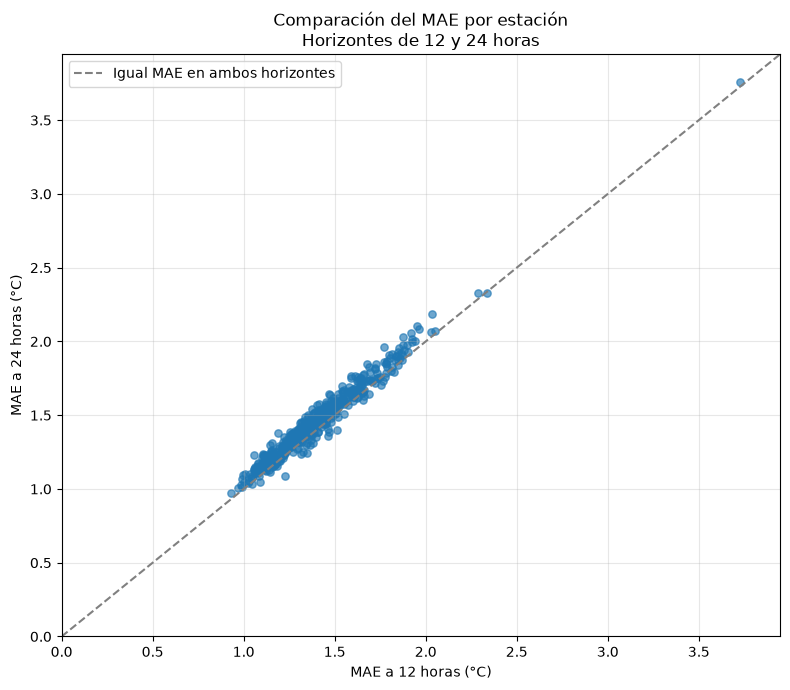

In [17]:

# ==========================================
# 12. COMPARACIÓN DEL MAE ENTRE HORIZONTES
# ==========================================

# Organizar el MAE por estación y horizonte
comparacion_mae = df_error_estaciones.pivot(
    index="station_id",
    columns="horizon_target_hours",
    values="mae_c"
)

# Organizar la cantidad de registros por estación
comparacion_n = df_error_estaciones.pivot(
    index="station_id",
    columns="horizon_target_hours",
    values="n"
)

# Conservar las estaciones con al menos 100 registros
# válidos en ambos horizontes para esta visualización
minimo_registros = 100

estaciones_suficientes = (
    (comparacion_n[12] >= minimo_registros)
    & (comparacion_n[24] >= minimo_registros)
)

datos_grafico = comparacion_mae.loc[
    estaciones_suficientes, [12, 24]
].dropna()

# Diferencia de MAE entre horizontes
diferencia_mae = (
    datos_grafico[24] - datos_grafico[12]
)

print("Estaciones totales:", len(comparacion_mae))
print("Estaciones representadas:", len(datos_grafico))

print("\nEstaciones con mayor MAE a 24 h:")
print((diferencia_mae > 0).sum())

print("\nEstaciones con mayor MAE a 12 h:")
print((diferencia_mae < 0).sum())

print("\nMediana de la diferencia (24 h - 12 h):")
print(round(diferencia_mae.median(), 3), "°C")

# Gráfico de dispersión
fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    datos_grafico[12],
    datos_grafico[24],
    alpha=0.65,
    s=28
)

# Línea de igualdad
limite = max(
    datos_grafico[12].max(),
    datos_grafico[24].max()
) * 1.05

ax.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="gray",
    label="Igual MAE en ambos horizontes"
)

ax.set_xlim(0, limite)
ax.set_ylim(0, limite)

ax.set_title(
    "Comparación del MAE por estación\n"
    "Horizontes de 12 y 24 horas"
)

ax.set_xlabel("MAE a 12 horas (°C)")
ax.set_ylabel("MAE a 24 horas (°C)")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()



### 12.1. Comparación del error entre horizontes

Se comparó el MAE de temperatura de los horizontes de 12 y 24 horas para las estaciones meteorológicas del conjunto seleccionado.

Para la visualización se consideraron estaciones con al menos 100 registros válidos de tipo `interval` en ambos horizontes.

**Resultados:**

- Estaciones comparadas: 514 de 519.
- Estaciones con mayor MAE a 24 horas: 456 (88,7 %).
- Estaciones con mayor MAE a 12 horas: 58 (11,3 %).
- Mediana de la diferencia de MAE (24 h − 12 h): +0,059 °C.

**Interpretación:**

Se observa que la mayoría de las estaciones presenta un MAE ligeramente superior en el horizonte de 24 horas.

Los puntos del gráfico se concentran cerca de la línea de igualdad, lo que sugiere que las estaciones con errores elevados en un horizonte también tienden a presentar errores elevados en el otro.

**Implicancias para el modelado:**

Los resultados justifican considerar el horizonte de predicción como una variable relevante para explicar el error meteorológico.

La comparación es descriptiva y no establece por sí sola la significación estadística de las diferencias.

Las métricas definitivas se evaluarán posteriormente sobre conjuntos de prueba temporales.


Distribución del sesgo por horizonte:


,count,min,median,max
horizon_target_hours,,,,
12,514,-2.775,0.021,1.953
24,514,-2.790,0.034,1.979



Signo del sesgo por horizonte:


signo_sesgo,Negativo,Positivo
horizon_target_hours,,
12,250,264
24,243,271


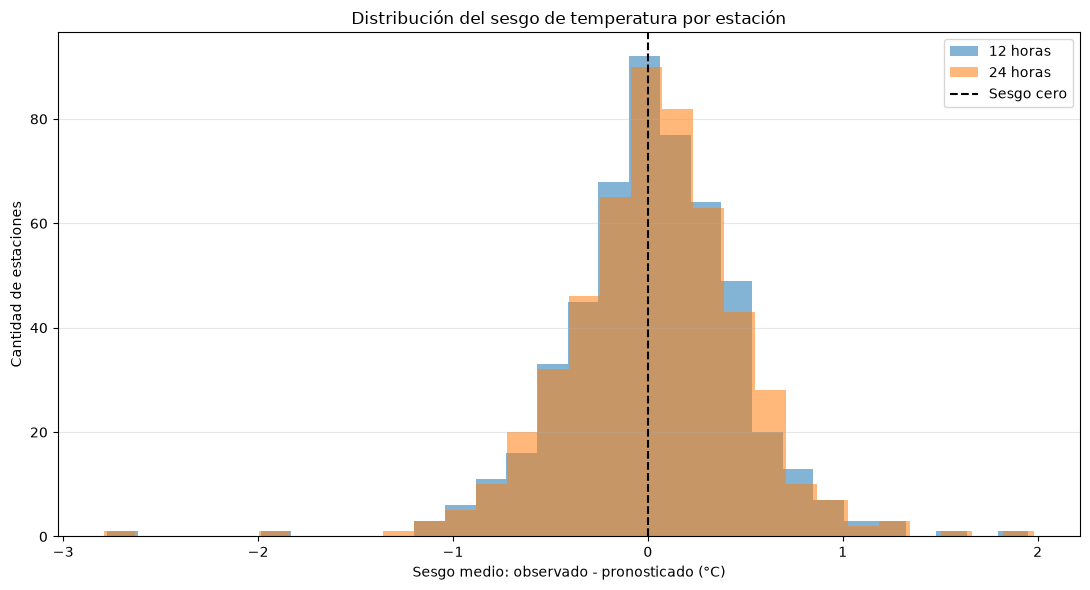

In [18]:

# ==========================================
# 13. DISTRIBUCIÓN DEL SESGO POR ESTACIÓN
# ==========================================

# Seleccionar estaciones con al menos 100 registros
datos_sesgo = df_error_estaciones[
    df_error_estaciones["n"] >= 100
].copy()

# Separar ambos horizontes
sesgo_12h = datos_sesgo[
    datos_sesgo["horizon_target_hours"] == 12
]["sesgo_c"]

sesgo_24h = datos_sesgo[
    datos_sesgo["horizon_target_hours"] == 24
]["sesgo_c"]

# Resumen estadístico
print("Distribución del sesgo por horizonte:")

display(
    datos_sesgo
    .groupby("horizon_target_hours")["sesgo_c"]
    .agg(["count", "min", "median", "max"])
    .round(3)
)

# Estaciones con sesgo positivo y negativo
print("\nSigno del sesgo por horizonte:")

resumen_signo = (
    datos_sesgo
    .assign(
        signo_sesgo=np.select(
            [
                datos_sesgo["sesgo_c"] > 0,
                datos_sesgo["sesgo_c"] < 0
            ],
            ["Positivo", "Negativo"],
            default="Cero"
        )
    )
    .groupby(["horizon_target_hours", "signo_sesgo"])
    .size()
    .unstack(fill_value=0)
)

display(resumen_signo)

# Histograma comparativo
fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    sesgo_12h,
    bins=30,
    alpha=0.55,
    label="12 horas"
)

ax.hist(
    sesgo_24h,
    bins=30,
    alpha=0.55,
    label="24 horas"
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Sesgo cero"
)

ax.set_title(
    "Distribución del sesgo de temperatura por estación"
)

ax.set_xlabel(
    "Sesgo medio: observado - pronosticado (°C)"
)

ax.set_ylabel("Cantidad de estaciones")

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()



### 13.1. Interpretación del sesgo por estación

Se analizó la distribución del sesgo medio de temperatura para los horizontes de 12 y 24 horas, considerando estaciones con al menos 100 registros válidos.

**Resultados:**

- Se analizaron 514 estaciones en cada horizonte.
- Para 12 horas, 264 estaciones presentaron sesgo positivo y 250 negativo.
- Para 24 horas, 271 estaciones presentaron sesgo positivo y 243 negativo.
- Las medianas fueron de +0,021 °C y +0,034 °C, respectivamente.
- Se identificaron sesgos individuales desde aproximadamente −2,8 °C hasta +2,0 °C.

**Interpretación:**

Aunque el sesgo global del pronóstico es pequeño, existen estaciones con tendencias sistemáticas de sobreestimación o subestimación.

La presencia de sesgos de signos opuestos permite que sus efectos se compensen parcialmente en las métricas globales.

Las distribuciones de los dos horizontes presentan comportamientos similares.

**Implicancias para el modelado:**

Los resultados justifican evaluar un baseline de corrección del sesgo histórico por estación.

El sesgo utilizado para realizar correcciones deberá calcularse exclusivamente con datos de entrenamiento, respetando la separación temporal.

También se investigará si los sesgos presentan patrones geográficos.


In [19]:

# ==========================================
# 14. ESTACIONES CON SESGOS EXTREMOS
# ==========================================

# Utilizar solamente estaciones con al menos
# 100 registros válidos por horizonte
datos_extremos = df_error_estaciones[
    df_error_estaciones["n"] >= 100
].copy()

columnas_mostrar = [
    "station_id",
    "state",
    "n",
    "sesgo_c",
    "mae_c",
    "rmse_c"
]

for horizonte in [12, 24]:

    datos_h = datos_extremos[
        datos_extremos["horizon_target_hours"] == horizonte
    ]

    print(f"\nHORIZONTE DE {horizonte} HORAS")

    print("\nCinco estaciones con mayor sobreestimación:")
    display(
        datos_h.nsmallest(5, "sesgo_c")[
            columnas_mostrar
        ].round(3)
    )

    print("\nCinco estaciones con mayor subestimación:")
    display(
        datos_h.nlargest(5, "sesgo_c")[
            columnas_mostrar
        ].round(3)
    )



HORIZONTE DE 12 HORAS

Cinco estaciones con mayor sobreestimación:


,station_id,state,n,sesgo_c,mae_c,rmse_c
76,AT326,TN,181,-2.775,3.727,4.251
356,F6574,VA,518,-1.932,2.337,3.041
170,D3435,TN,549,-1.152,1.721,2.187
734,KHYW,SC,937,-1.143,1.608,2.074
376,F9865,NH,593,-1.051,1.574,2.001



Cinco estaciones con mayor subestimación:


,station_id,state,n,sesgo_c,mae_c,rmse_c
1012,SECN3,NH,724,1.953,2.289,2.861
414,G2857,VT,536,1.535,1.921,2.279
996,MSWV1,VT,768,1.287,1.781,2.273
864,KOQU,RI,733,1.232,1.620,1.972
316,F1341,DC,609,1.223,1.604,1.882



HORIZONTE DE 24 HORAS

Cinco estaciones con mayor sobreestimación:


,station_id,state,n,sesgo_c,mae_c,rmse_c
77,AT326,TN,178,-2.790,3.758,4.279
357,F6574,VA,518,-1.896,2.328,2.909
171,D3435,TN,549,-1.226,1.813,2.257
377,F9865,NH,593,-1.129,1.626,2.060
735,KHYW,SC,938,-1.090,1.623,2.134



Cinco estaciones con mayor subestimación:


,station_id,state,n,sesgo_c,mae_c,rmse_c
1013,SECN3,NH,721,1.979,2.327,2.885
415,G2857,VT,537,1.579,2.059,2.446
997,MSWV1,VT,768,1.288,1.852,2.332
317,F1341,DC,609,1.264,1.645,1.954
865,KOQU,RI,736,1.258,1.615,1.962


Estaciones representadas: 514
Estaciones sin coordenadas: 0


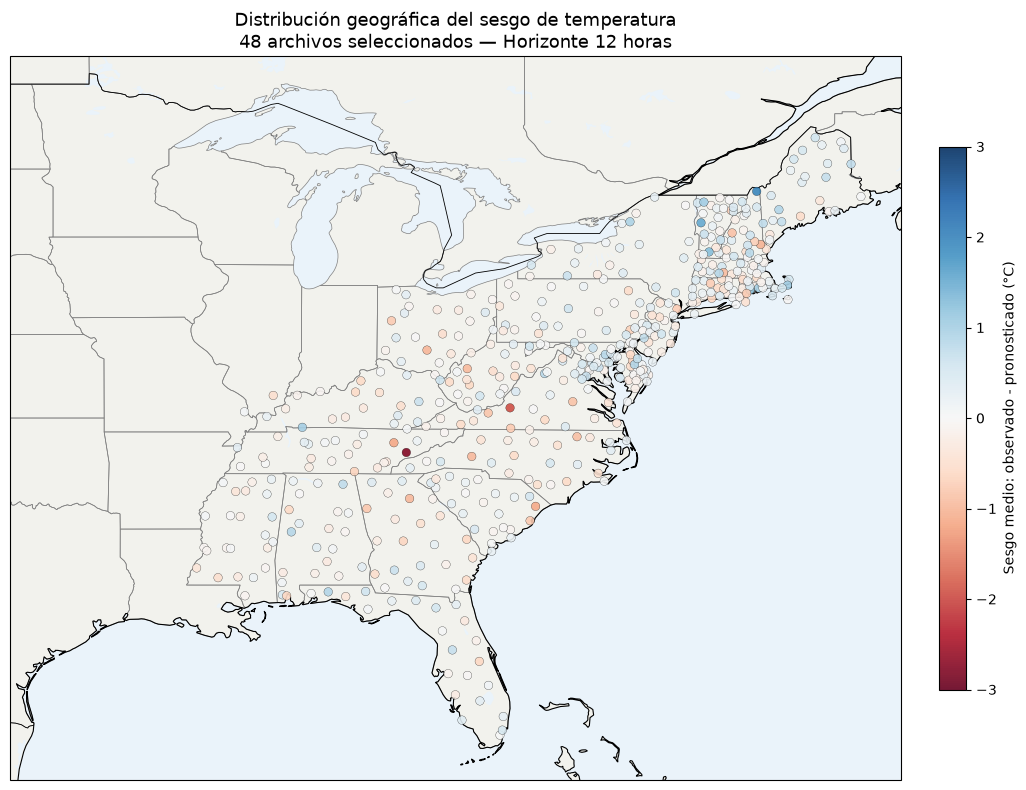

In [20]:

# ==========================================
# 15. MAPA GEOGRÁFICO DEL SESGO DE TEMPERATURA
# ==========================================

from matplotlib.colors import TwoSlopeNorm

# Seleccionar estaciones del horizonte de 12 horas
# con al menos 100 observaciones válidas
sesgos_mapa = df_error_estaciones[
    (df_error_estaciones["horizon_target_hours"] == 12)
    & (df_error_estaciones["n"] >= 100)
][
    ["station_id", "state", "n", "sesgo_c"]
].copy()

# Recuperar las coordenadas geográficas
coordenadas = df_periodo_estaciones[
    df_periodo_estaciones["horizon_target_hours"] == 12
][
    ["station_id", "latitude", "longitude"]
].copy()

mapa_sesgos = sesgos_mapa.merge(
    coordenadas,
    on="station_id",
    how="left",
    validate="one_to_one"
)

print("Estaciones representadas:", len(mapa_sesgos))
print(
    "Estaciones sin coordenadas:",
    mapa_sesgos[["latitude", "longitude"]]
    .isna().any(axis=1).sum()
)

# Crear el mapa
proyeccion = ccrs.PlateCarree()

fig, ax = plt.subplots(
    figsize=(13, 8),
    subplot_kw={"projection": proyeccion}
)

ax.set_extent([-98, -66, 24, 50], crs=proyeccion)

# Capas geográficas
ax.add_feature(cfeature.OCEAN, facecolor="#eaf3fa")
ax.add_feature(cfeature.LAND, facecolor="#f2f2ed")
ax.add_feature(cfeature.LAKES, facecolor="#eaf3fa")

ax.add_feature(
    cfeature.STATES,
    edgecolor="gray",
    linewidth=0.5
)

ax.add_feature(
    cfeature.COASTLINE,
    edgecolor="black",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.6
)

# Escala divergente centrada en cero
escala = TwoSlopeNorm(
    vmin=-3,
    vcenter=0,
    vmax=3
)

# Dibujar estaciones
puntos = ax.scatter(
    mapa_sesgos["longitude"],
    mapa_sesgos["latitude"],
    c=mapa_sesgos["sesgo_c"],
    cmap="RdBu",
    norm=escala,
    s=38,
    edgecolor="black",
    linewidth=0.2,
    alpha=0.9,
    transform=proyeccion,
    zorder=5
)

# Barra de colores
barra = fig.colorbar(
    puntos,
    ax=ax,
    shrink=0.75,
    pad=0.03
)

barra.set_label(
    "Sesgo medio: observado - pronosticado (°C)"
)

# Título
ax.set_title(
    "Distribución geográfica del sesgo de temperatura\n"
    "48 archivos seleccionados — Horizonte 12 horas",
    fontsize=13
)

plt.tight_layout()
plt.show()



### 15.1. Interpretación de la distribución geográfica del sesgo

Se representó espacialmente el sesgo medio de temperatura de las estaciones meteorológicas para el horizonte de 12 horas.

Se utilizaron los 48 archivos seleccionados y se incluyeron 514 estaciones con al menos 100 registros válidos de tipo `interval`.

La escala de colores se centró en cero para distinguir sobreestimaciones y subestimaciones.

**Resultados:**

- La mayoría de las estaciones presenta sesgos relativamente pequeños, representados mediante tonalidades próximas al blanco.
- Se identificaron estaciones con sobreestimaciones importantes en distintas regiones, incluyendo Tennessee y Virginia.
- También se observaron estaciones con subestimaciones relevantes en el noreste de Estados Unidos.
- No se aprecia visualmente una división geográfica uniforme entre las estaciones con sesgo positivo y negativo.
- Algunas estaciones geográficamente cercanas presentan sesgos de diferente magnitud y signo.

**Interpretación:**

El sesgo del pronóstico presenta heterogeneidad espacial y diferencias entre estaciones meteorológicas.

La ubicación geográfica podría aportar información predictiva, aunque no parece suficiente por sí sola para explicar todos los errores observados.

La representación visual no permite establecer relaciones causales ni demostrar la existencia o ausencia de dependencia espacial.

**Implicancias para el modelado:**

Se propone evaluar la utilidad de:

- La identificación de la estación meteorológica.
- Las coordenadas geográficas.
- Los atributos meteorológicos pronosticados.
- La información histórica de errores.
- Las características de estaciones geográficamente cercanas.

Las variables históricas deberán calcularse exclusivamente con información disponible antes del momento de predicción, evitando filtraciones de información futura.
